# The robot librarian in MuJoCo: from book labels to an RL-ready POMDP

This notebook assumes you have **never used MuJoCo** and haven't read the rest of this repo. By the end you
will have run, end to end, in simulation:

1. **perceive** the labels on the books' spines (real spine photos from PBBM-robot-librarian),
2. **decide where** the held book belongs (alphabetical order),
3. **adjust** the row if needed (widen a tight gap, stand up a leaning neighbour),
4. **insert** the book,

and wrapped all of it as a **POMDP environment** that a deep-RL agent can be trained in.

### Short answer to "can we port robot-librarian to MuJoCo and train it?"

**Yes, but port the *task* and the *data*, not the code.** PBBM is ROS + MoveIt + a PR2 with a Shadow Hand. None
of that runs in MuJoCo, and our robot is a Panda. What ports cleanly: the book database and spine images
(§3), their matching and belief-fusion algorithms (§4), and their decision logic and placing strategy
(§5-6, and notebook 02).

For RL, **don't train one network from pixels to joint torques for the whole flow.** The reward
("book shelved in the right place, nothing knocked over") comes once, after tens of thousands of physics
steps. Exploration from scratch won't find it. What works in practice is a **hierarchy**:

| Layer | Decides | How to train it |
|---|---|---|
| Perception | which book is which, where the gap is | **supervised** (labels are free in sim) |
| High level | which slot, which adjustment skill, its parameters | **RL** over a few discrete or continuous choices per book |
| Low level | the motion of each skill | start from the **scripted skills** we already have, then learn a **residual** correction with RL |

§7 writes this as a POMDP, §8 builds a first environment, §9 runs the whole job on a book-return cart, §10 is what building all that taught us, §11 is the revised, scenario-agnostic approach it led to, and §12 is the roadmap.

> Run from the repo root or from `notebooks/`. Everything uses the packages in `pyproject.toml`
> (`uv sync`). Cells that run a full insertion take ~5-10 s each.

In [1]:
import csv, math, os, sys, time
import xml.etree.ElementTree as ET
import numpy as np
import matplotlib.pyplot as plt
import mediapy
import mujoco

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)

from bila.control import insert_book

from bila.sim import shelf_scene
from bila.sim.shelf_scene import ShelfConfig, sample_row, settle, book_tilt_deg, _f
from bila.control.insert_book import Episode, ShelfFrame, build_model, report, DEFAULT_PANDA
from bila.vision.perception import GroundTruthPerception
print("MuJoCo", mujoco.__version__)

MuJoCo 3.17.0


## 1. MuJoCo in five minutes

MuJoCo is a physics engine. You give it a **model**, and it advances the world in small time steps.

- **MJCF XML** is a text file describing bodies, their shapes (*geoms*), joints, motors (*actuators*), sensors
  and cameras. `shelf_scene.build_scene()` *writes* this XML for a random bookcase.
- **`MjModel`** is the compiled XML. Everything that doesn't change while it runs is here: sizes, masses, joint
  limits, actuator gains.
- **`MjData`** is everything that changes: joint positions `qpos`, velocities `qvel`, motor commands
  `ctrl`, sensor readings `sensordata`, current contacts, and time.
- **`mujoco.mj_step(model, data)`** advances `data` by `model.opt.timestep` (2 ms here). That's the whole loop:
  set `data.ctrl`, step, read `data`.

A *free* body (a book that can fall over) has 7 numbers in `qpos`: position xyz + orientation quaternion
wxyz. A *hinge* joint (an arm joint) has 1.

In this repo, `insert_book.make_episode()` samples a random bookcase, adds the Panda and the book to
insert, compiles it, and lets physics **settle** the row, so leaning books come to a real resting pose.

In [2]:
cfg = ShelfConfig()
model, data, row = insert_book.make_episode(cfg, "tight", np.random.default_rng(0), DEFAULT_PANDA)

print(f"qpos size {model.nq}, qvel size {model.nv}, actuators {model.nu}, timestep {model.opt.timestep} s")
print("actuators :", [model.actuator(i).name for i in range(model.nu)])
print("sensors   :", [model.sensor(i).name for i in range(model.nsensor)])
print("cameras   :", [model.camera(i).name for i in range(model.ncam)])
print("arm joints + fingers (first 9 of qpos):", np.round(data.qpos[:9], 3))
b = row.books[0]
adr = model.jnt_qposadr[model.body(b.name).jntadr[0]]
print(f"{b.name}: free joint qpos = {np.round(data.qpos[adr:adr + 7], 3)}  (x y z, qw qx qy qz)")
print(f"target row: {len(row.books)} books, the new book goes between books[{row.target_index - 1}] and books[{row.target_index}]")
print(f"gap {1000 * (row.gap_right - row.gap_left):.0f} mm for a {1000 * row.target_book.thickness:.0f} mm book (tight!)")

qpos size 135, qvel size 117, actuators 8, timestep 0.002 s
actuators : ['panda/actuator1', 'panda/actuator2', 'panda/actuator3', 'panda/actuator4', 'panda/actuator5', 'panda/actuator6', 'panda/actuator7', 'panda/actuator8']
sensors   : ['panda/ft_force', 'panda/ft_torque']
cameras   : ['scene_cam', 'panda/wrist_cam']
arm joints + fingers (first 9 of qpos): [ 0.    -0.6    0.    -2.6    0.     2.     0.785  0.04   0.04 ]
book_0: free joint qpos = [-0.269  0.028  0.878  1.    -0.     0.     0.003]  (x y z, qw qx qy qz)
target row: 17 books, the new book goes between books[4] and books[5]
gap 33 mm for a 48 mm book (tight!)


**Actuators 1-7** are *position* servos on the arm joints: write a target angle into `data.ctrl[i]` and the joint
moves there. **Actuator 8** is the gripper (0 = closed, 255 = open). The **F/T sensor** at the wrist gives force
and torque. This is how the scripted skills feel when a book stops moving (PBBM's guarded moves do the same).

Let's step physics for one second, holding the arm still, and read the sensor:

In [3]:
d = mujoco.MjData(model); d.qpos[:] = data.qpos      # a scratch copy, so `data` stays as settled
mujoco.mj_forward(model, d)
d.ctrl[:7] = d.qpos[:7]                              # hold the current joint angles
for _ in range(int(1.0 / model.opt.timestep)):
    mujoco.mj_step(model, d)
print("time", round(d.time, 3), "s | wrist force (N):", np.round(d.sensor("panda/ft_force").data, 2))

time 1.0 s | wrist force (N): [-0.    0.   -7.46]


**Cameras.** `mujoco.Renderer` draws offscreen images from any camera: RGB, depth, or **segmentation** (which
geom each pixel belongs to). `scene_cam` overlooks the row. `panda/wrist_cam` is on the hand.

scene_cam,wrist_cam RGB,wrist_cam depth (m)

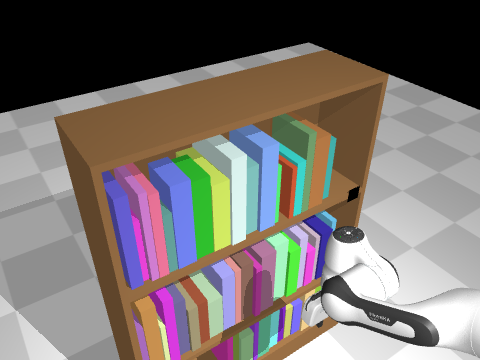
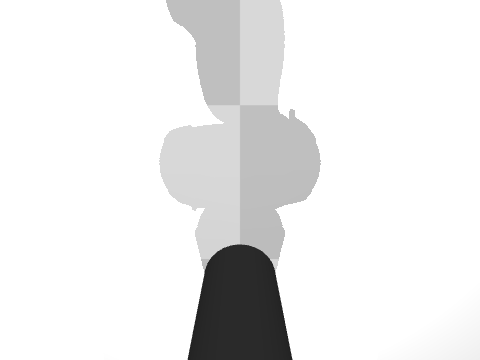
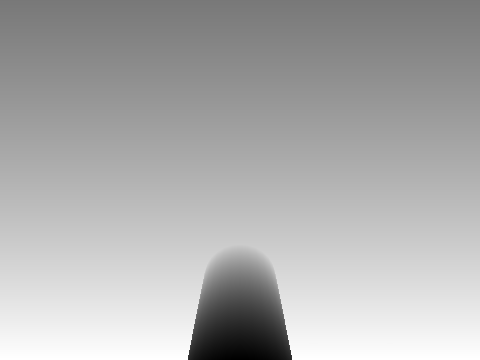

In [4]:
def render(model, data, camera, size=(360, 480), mode="rgb"):
    with mujoco.Renderer(model, *size) as r:
        if mode == "depth": r.enable_depth_rendering()
        if mode == "seg": r.enable_segmentation_rendering()
        r.update_scene(data, camera=camera)
        out = r.render()
    return out[..., 0] if mode == "seg" else out        # seg: geom id per pixel (-1 = background)

depth = render(model, data, "panda/wrist_cam", mode="depth")
mediapy.show_images([render(model, data, "scene_cam"), render(model, data, "panda/wrist_cam"),
                     np.clip(depth, 0, 2) / 2], titles=["scene_cam", "wrist_cam RGB", "wrist_cam depth (m)"])

## 2. The scenarios

`sample_row(cfg, scenario, rng)` picks the bookcase, the books and the **target slot**. The scenario decides
what state the slot is in, and so which adjustment is needed before inserting:

| scenario | slot | adjustment needed | scripted skill (`insert_book.Episode`) |
|---|---|---|---|
| clear | wide enough | none | `insert()` |
| tight | narrower than the book | push neighbours apart | `insert_tight()` |
| leaning | a neighbour leans into it | stand it up, then as tight | `insert_leaning()` |
| packed | no gap at all | shove a run of books aside | `insert_packed()` (slow, ~2 min) |
| collapsed | a run of books has fallen over | not solved yet | none |

`shelf_scene.make_episode` builds without the robot and the held book (faster), which is enough to look:

clear,tight,leaning,collapsed,packed

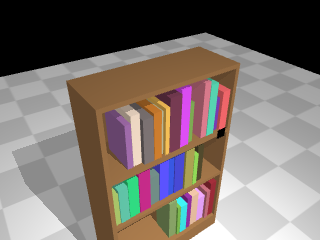
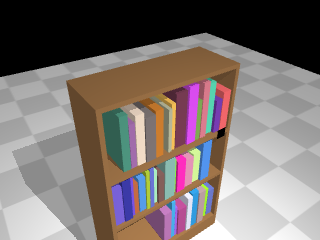
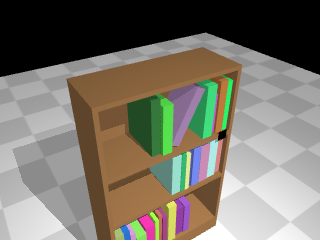
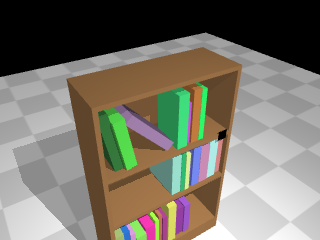
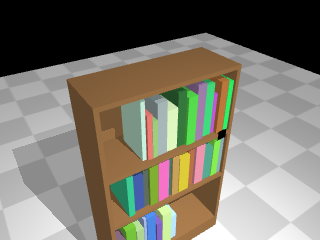

In [5]:
imgs = []
for sc in shelf_scene.SCENARIOS:
    m, dd, r, _ = shelf_scene.make_episode(cfg, sc, np.random.default_rng(3))
    imgs.append(render(m, dd, "scene_cam", size=(240, 320)))
mediapy.show_images(imgs, titles=list(shelf_scene.SCENARIOS))

## 3. Porting PBBM's book labels

PBBM's `books.csv` lists 15 real books, and `spines/id_N.png` has a photo of each spine. We paste those photos
onto our books' spines as **textures**. The label decides **where the book belongs**: we make the row
alphabetical by title around the slot, so the generator's slot is also the *correct* place for the held
book.

How it's done:
- `assign_labels` picks distinct database books for up to 3 books on each side of the slot, plus the held book,
  sorted by title so the held book's title falls between its neighbours'. The rest of the row stays plain
  (unlabelled, as if their labels can't be read).
- `decorate` edits the generated XML. Per labelled book it adds a texture and a **thin, massless,
  non-colliding box** on the spine face. Physics is unchanged, so every scripted skill still works.
  It also adds `spine_cam`, a fixed camera in front of the slot (think head camera, like PBBM's Kinect).
- `insert_book.build_model` calls `build_scene` internally, so `build_labelled_model` swaps in a decorated
  `build_scene` for that one call.

In [6]:
LIB = os.path.join(ROOT, "PBBM-robot-librarian", "librarian_common", "librarian_resources")
DB = {int(r["id"]): r for r in csv.DictReader(open(os.path.join(LIB, "books.csv"), encoding="utf-8"))}
title = lambda i: DB[i]["title"].lower()

def assign_labels(row, rng, k=3):
    # {book name: database id}, alphabetical across the slot
    ti = row.target_index
    left = [row.books[i].name for i in range(max(0, ti - k), ti)]
    right = [row.books[i].name for i in range(ti, min(len(row.books), ti + k))]
    picks = sorted(map(int, rng.choice(sorted(DB), len(left) + 1 + len(right), replace=False)), key=title)
    return dict(zip(left + [row.target_book.name] + right, picks))

def decorate(xml, row, labels, cam_standoff=0.20):
    root = ET.fromstring(xml)
    asset = root.find("asset")
    for i in set(labels.values()):
        ET.SubElement(asset, "texture", name=f"spine{i}", type="2d", hflip="true",
                      file=os.path.join(LIB, "spines", f"id_{i}.png"))
        ET.SubElement(asset, "material", name=f"spine{i}", texture=f"spine{i}")
    books = {b.name: b for b in row.books}
    for body in root.iter("body"):
        b = books.get(body.get("name"))
        if b is not None and b.name in labels:          # box: thickness along x, depth along y (spine at +y), height along z
            ET.SubElement(body, "geom", type="box", name=b.name + "_label", material=f"spine{labels[b.name]}",
                          size=_f(b.thickness / 2 * 0.98, 0.0005, b.height / 2 * 0.98),
                          pos=_f(0, b.depth / 2 + 0.0006, 0), contype="0", conaffinity="0", mass="0")
    f = ShelfFrame(row)
    pos = f.to_world(np.array([(row.gap_left + row.gap_right) / 2, row.shelf_depth / 2 + cam_standoff,
                               row.target_board_top + row.clear_height / 2]))
    xs, _, zs = f.R.T                                   # shelf axes in world; the camera looks along -y (into the shelf)
    ET.SubElement(root.find("worldbody"), "camera", name="spine_cam", pos=_f(*pos), xyaxes=_f(*(-xs), *zs), fovy="80")
    return ET.tostring(root, encoding="unicode")

def build_labelled_model(cfg, row, labels):
    orig = insert_book.build_scene
    insert_book.build_scene = lambda c, r, p=None: decorate(orig(c, r, p), row, labels)
    try:
        return build_model(cfg, row, DEFAULT_PANDA)
    finally:
        insert_book.build_scene = orig

def make_labelled_episode(cfg, scenario, rng, tries=10):
    for _ in range(tries):
        row = sample_row(cfg, scenario, rng)
        labels = assign_labels(row, rng)
        model = build_labelled_model(cfg, row, labels)
        data = mujoco.MjData(model)
        if settle(model, data, row)["stable"]:
            return model, data, row, labels
    raise RuntimeError("no stable row")

book_2       -> id  8  Betriebliche Expertensystem-Anwendungen
book_3       -> id 14  Der Kleine DUDEN
book_4       -> id 15  Die Suchfibel
target_book  -> id  5  GUI & Visualization Services Volume III
book_5       -> id 11  Innovations-management
book_6       -> id  7  Requirements-Engineering und-Management
book_7       -> id  6  THE TTL Data Book Volume 2


spine_cam,scene_cam

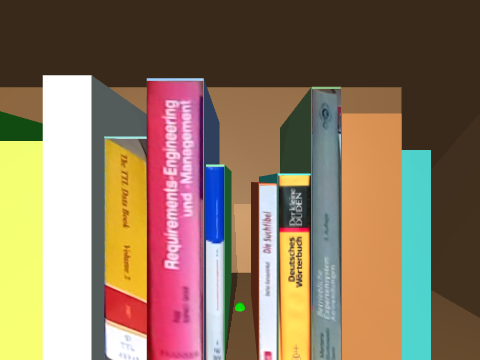
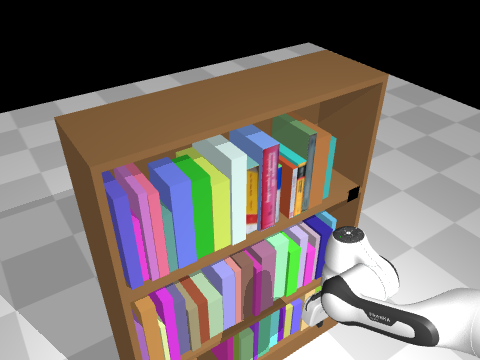

In [7]:
model, data, row, labels = make_labelled_episode(cfg, "tight", np.random.default_rng(0))
for name, i in labels.items():
    print(f"{name:12s} -> id {i:2d}  {DB[i]['title']}")
mediapy.show_images([render(model, data, "spine_cam"), render(model, data, "scene_cam")], titles=["spine_cam", "scene_cam"])

Note the direction: seen **from the front, row index increases to the left** of the image. The shelf frame's x
axis runs along the row away from the robot's right. Alphabetical order therefore reads right to left in
`spine_cam`.

## 4. Perception: reading the labels

Here we follow PBBM's recipe (notebook 02, §4):

1. **Find each spine.** PBBM: YOLOv5. Here: the segmentation image says which pixels belong to which label
   geom. This is a privileged shortcut that a detector replaces for sim-to-real.
2. **Describe it.** A hue-saturation histogram of the crop. PBBM's final version used CLIP embeddings.
3. **Score against the database** with cosine similarity, then assign **greedily and uniquely**.

In [8]:
def hs_hist(rgb, bins=16):
    x = rgb.reshape(-1, 3).astype(float) / 255
    mx, mn = x.max(1), x.min(1); c = mx - mn + 1e-9
    r, g, b = x.T
    h = np.where(mx == r, (g - b) / c % 6, np.where(mx == g, (b - r) / c + 2, (r - g) / c + 4)) / 6
    s = (mx - mn) / (mx + 1e-9)
    hist = np.histogram2d(h, s, bins=bins, range=[[0, 1], [0, 1]])[0].ravel()
    return hist / (np.linalg.norm(hist) + 1e-9)

IDS = sorted(DB)
DB_HIST = np.array([hs_hist(mediapy.read_image(os.path.join(LIB, "spines", f"id_{i}.png"))[..., :3]) for i in IDS])

def greedy_assign(S):
    S = S.astype(float).copy(); out = {}
    for _ in range(min(S.shape)):
        r, c = np.unravel_index(np.argmax(S), S.shape)
        out[int(r)] = int(c); S[r, :] = -np.inf; S[:, c] = -np.inf
    return out

def read_labels(model, data, row, rgb=None, seg=None, min_pixels=300):
    # {row index: (database id, score)} for every labelled spine visible in spine_cam
    rgb = render(model, data, "spine_cam") if rgb is None else rgb
    seg = render(model, data, "spine_cam", mode="seg") if seg is None else seg
    seen, crops = [], []
    for i, b in enumerate(row.books):
        gid = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_GEOM, b.name + "_label")
        mask = seg == gid
        if gid >= 0 and mask.sum() >= min_pixels:
            seen.append(i); crops.append(rgb[mask])
    if not seen:
        return {}
    S = np.array([DB_HIST @ hs_hist(c) for c in crops])
    return {seen[k]: (IDS[j], float(S[k, j])) for k, j in greedy_assign(S).items()}

read = read_labels(model, data, row)
for i, (pid, score) in sorted(read.items()):
    true = labels[row.books[i].name]
    print(f"books[{i}]  read id {pid:2d} (score {score:.2f})  true id {true:2d}  {'ok' if pid == true else 'WRONG'}")

books[2]  read id  8 (score 1.00)  true id  8  ok
books[3]  read id 14 (score 0.51)  true id 14  ok
books[4]  read id 15 (score 0.98)  true id 15  ok
books[5]  read id 11 (score 1.00)  true id 11  ok
books[6]  read id  7 (score 1.00)  true id  7  ok
books[7]  read id  6 (score 0.99)  true id  6  ok


In sim the spine you see *is* the reference photo, so this is nearly perfect. On a real camera, lighting, blur
and occlusion make it much harder. That's where domain randomisation (random lights, colours and camera
noise during training) and a learned matcher come in.

## 5. Deciding where to shelve

The held book's identity is known. PBBM's robot knew which book it had picked, and could inspect the cover.
The slot is where its title fits into the titles read from the row:

In [9]:
def choose_slot(read, held_id):
    # insert between books[s-1] and books[s]: before the first read book whose title comes after the held one
    known = sorted(read.items())                       # [(row index, (id, score))], in row order
    after = [i for i, (pid, _) in known if title(pid) > title(held_id)]
    return after[0] if after else known[-1][0] + 1

held = labels[row.target_book.name]
slot = choose_slot(read, held)
print(f"holding '{DB[held]['title']}' -> slot {slot}   (correct slot: {row.target_index})")

holding 'GUI & Visualization Services Volume III' -> slot 5   (correct slot: 5)


## 6. Adjusting the row and inserting

The slot's state decides the skill. Here a simple rule reads it from a **`ShelfEstimate`** (`bila/vision/perception.py`):
only what a front camera could measure, meaning spine corners, lean of the neighbours, and gap width by height.
`GroundTruthPerception` computes it exactly from the sim. `NoisyPerception` adds camera-like error.
`Episode.<skill>()` then runs the whole motion: IK, min-jerk paths, force-guarded pushes, and the score.

left lean +0.0 deg, right lean -0.0 deg, narrowest gap 34.6 mm, book 47.8 mm -> insert_tight


  SUCCESS [fingertip, one side]: tilt 0.0 deg, spine +1.4 mm from the neighbour's, released
  other books: most moved 82.1 mm (all together 154 mm), most tilted 0.0 deg | let go after 12.5 s, in place after 18.7 s


before,after (spine_cam),after (scene_cam)

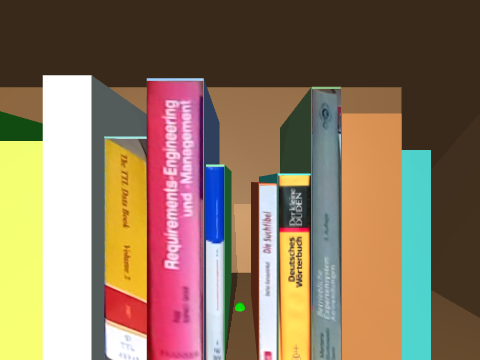
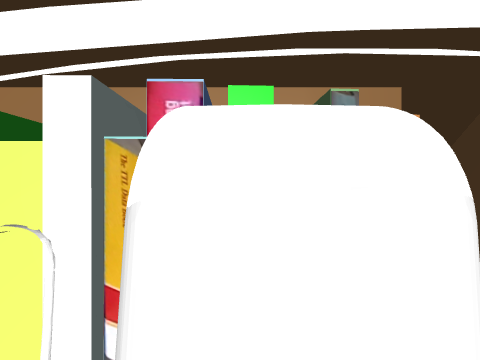
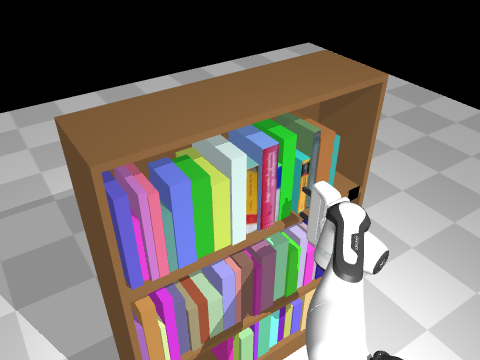

In [10]:
SKILLS = ("insert", "insert_tight", "insert_leaning", "insert_packed")

def choose_skill(est, thickness, lean_deg=5.0, margin=0.006, packed_below=0.008):
    leans = [abs(math.degrees(b.lean)) for k in (-1, 1) if (b := est.book(k)) is not None]
    if leans and max(leans) > lean_deg:
        return "insert_leaning"
    gap = est.min_gap_width(0.25)
    if gap < packed_below:
        return "insert_packed"
    return "insert_tight" if gap < thickness + margin else "insert"

est = GroundTruthPerception(model, row).estimate(data)
skill = choose_skill(est, row.target_book.thickness)
print(f"left lean {math.degrees(est.book(-1).lean):+.1f} deg, right lean {math.degrees(est.book(1).lean):+.1f} deg, "
      f"narrowest gap {1000 * est.min_gap_width(0.25):.1f} mm, book {1000 * row.target_book.thickness:.1f} mm -> {skill}")

before = render(model, data, "spine_cam")
res = getattr(Episode(model, data, row, None, log=lambda *a: None), skill)()
print(report(res))
mediapy.show_images([before, render(model, data, "spine_cam"), render(model, data, "scene_cam")],
                    titles=["before", "after (spine_cam)", "after (scene_cam)"])

`res` carries everything a reward needs: `success`, `upright`, `in_place`, `released`, `neighbour_shift_m`,
`neighbour_tilt_change_deg`, `time_to_seat_s`, and so on.

## 7. The task as a POMDP

A **POMDP** (partially observable Markov decision process) is a tuple $(S, A, T, R, \Omega, O, \gamma)$. The agent
never sees the state $s$, only observations $o$, so it acts on a **belief** (a summary of what it has seen).

| POMDP part | In this project | Where in the code |
|---|---|---|
| **State** $s$ | every body's pose and velocity (`qpos`, `qvel`), plus hidden book properties: depth, mass, friction, true identity | `MjData`, `Row` |
| **Observation** $o$ | `spine_cam` / `wrist_cam` RGB-D, wrist F/T, arm joint angles, the held book's label | `render(...)`, `d.sensor("panda/ft_force")`, `d.qpos[:9]` |
| **Belief** $b$ | which book is where (read labels), the `ShelfEstimate`, plus memory of past frames | `read_labels`, `bila/vision/perception.py`. PBBM: k-means over 10 frames. RL: a recurrent policy or frame stack. |
| **Action** $a$ | high level: slot + skill (+ skill parameters). Low level: Cartesian setpoint or joint targets every 2-20 ms | `choose_slot`, `choose_skill`; `Episode` (its `Runner` re-solves IK every step) |
| **Transition** $T$ | MuJoCo physics | `mj_step` |
| **Reward** $R$ | + book in the right slot, upright, seated, released; − neighbours moved or toppled; − time | `res` from `Episode.score()` |
| **Ω, O** | the camera and sensor models, including noise | `NoisyPerception`, image noise you add |

**Why it's *partially* observable.** The camera sees spines, not books. Depth front-to-back, mass and friction
are hidden. Labels can be misread or occluded (by the hand, too). Whether a neighbour will slide or swivel when
pushed only shows once you push. That's why the scripted skills re-measure after every push and use force
thresholds. An RL policy needs the same: **memory** (an LSTM/GRU or stacked frames) and **force feedback**.

## 8. An environment an RL agent can train in

Below is a small environment with the usual `reset()` / `step()` interface (the Gymnasium API, without needing
the package). It is the **high level** of the hierarchy: one decision per book. This is **version 1**: §10 explains why it is replaced by the sequential, scenario-agnostic environment of §11.

- **observation**: `spine_cam` RGB, the held book's spine image, wrist force, arm joints
- **action**: `(slot, skill)`, where `slot` is in `0..len(row)` and `skill` indexes `SKILLS`
- **reward**: −1 for the wrong slot (episode ends, nothing is executed). Otherwise run the skill: +1 if it succeeds,
  −0.5 if it fails or can't plan, minus 0.05 per degree a neighbour tipped.

Packed is left out of the default mix because its skill takes ~2 minutes of compute per episode.

In [11]:
class LibrarianEnv:
    def __init__(self, scenarios=("clear", "tight", "leaning"), cfg=None, size=(240, 320)):
        self.scenarios, self.cfg, self.size = scenarios, cfg or ShelfConfig(), size
        self.held_img = {i: mediapy.read_image(os.path.join(LIB, "spines", f"id_{i}.png"))[..., :3] for i in DB}

    def reset(self, seed=None):
        self.rng = np.random.default_rng(seed)
        self.scenario = str(self.rng.choice(self.scenarios))
        self.model, self.data, self.row, self.labels = make_labelled_episode(self.cfg, self.scenario, self.rng)
        return self._obs(), {"scenario": self.scenario}

    def _obs(self):
        m, d = self.model, self.data
        return {"rgb": render(m, d, "spine_cam", self.size), "seg": render(m, d, "spine_cam", self.size, "seg"),
                "held_spine": self.held_img[self.labels[self.row.target_book.name]],
                "force": d.sensor("panda/ft_force").data.copy(), "arm_q": d.qpos[:9].copy()}

    def step(self, action):
        slot, skill = int(action[0]), SKILLS[int(action[1])]
        info = {"scenario": self.scenario, "skill": skill, "correct_slot": self.row.target_index}
        if slot != self.row.target_index:
            return self._obs(), -1.0, True, False, {**info, "result": "wrong slot"}
        try:
            res = getattr(Episode(self.model, self.data, self.row, None, log=lambda *a: None), skill)()
        except (RuntimeError, ValueError) as e:            # the skill found no safe way to do it
            return self._obs(), -0.5, True, False, {**info, "result": f"failed: {e}"}
        reward = (1.0 if res["success"] else -0.5) - 0.05 * res.get("neighbour_tilt_change_deg", 0.0)
        return self._obs(), reward, True, False, {**info, "result": "success" if res["success"] else "failed", "res": res}

Two policies to compare. The **modular** policy is PBBM's pipeline ported: read labels → sorted-title slot →
rule-based skill. The **random** policy is what an untrained RL agent does at first. The third policy is given the
correct slot but picks the skill at random, which shows that the skill choice has to be learned too. Note that the
modular policy only uses things in the observation: it reads labels from the image and the held book from its
spine. It also uses a `ShelfEstimate`, which `GroundTruthPerception` computes from the sim's poses, standing in
for an RGB-D estimate.

In [12]:
def modular_policy(env, obs):
    m, d, row = env.model, env.data, env.row
    read = read_labels(m, d, row, obs["rgb"], obs["seg"], min_pixels=80)
    held = IDS[int(np.argmax(DB_HIST @ hs_hist(obs["held_spine"])))]
    est = GroundTruthPerception(m, row).estimate(d)
    return choose_slot(read, held), SKILLS.index(choose_skill(est, row.target_book.thickness))

def random_policy(env, obs):
    return env.rng.integers(0, len(env.row.books) + 1), env.rng.integers(0, 3)

def right_slot_random_skill(env, obs):                 # cheats on the slot, to show that the skill choice matters too
    return env.row.target_index, env.rng.integers(0, 3)

env = LibrarianEnv()
for name, policy in [("modular", modular_policy), ("random", random_policy), ("slot+rnd", right_slot_random_skill)]:
    total = 0.0
    for seed in range(3):
        obs, info = env.reset(seed)
        t = time.time()
        obs, r, done, _, info = env.step(policy(env, obs))
        total += r
        print(f"{name:8s} seed {seed} {info['scenario']:8s} -> {info['skill']:15s} {info['result']:12s} reward {r:+.2f}  ({time.time() - t:.1f} s)")
    print(f"{name}: mean reward {total / 3:+.2f}\n")

modular  seed 0 leaning  -> insert_leaning  success      reward +1.00  (4.2 s)


modular  seed 1 tight    -> insert_tight    success      reward +1.00  (8.4 s)


modular  seed 2 leaning  -> insert_leaning  success      reward +1.00  (3.3 s)
modular: mean reward +1.00



random   seed 0 leaning  -> insert_tight    wrong slot   reward -1.00  (0.1 s)


random   seed 1 tight    -> insert_leaning  wrong slot   reward -1.00  (0.1 s)


random   seed 2 leaning  -> insert          wrong slot   reward -1.00  (0.1 s)
random: mean reward -1.00



slot+rnd seed 0 leaning  -> insert_leaning  success      reward +1.00  (4.2 s)


slot+rnd seed 1 tight    -> insert          failed: the book jammed at the slot's entrance reward -0.50  (4.4 s)


slot+rnd seed 2 leaning  -> insert          failed       reward -0.63  (4.2 s)
slot+rnd: mean reward -0.04



## 9. The whole job on a book-return cart

`bila/control/cart_demo.py` puts the pieces above together the way a librarian would. The Panda rides a **lift** on a wheeled
cart with a **return tray** of books standing spine-up. It reads the call numbers in the tray (`tray_cam`), looks
each one up in the shelf map to find its row, raises the lift to that row, **leans the arm out of `row_cam`'s view**
and reads the spines to find the slot, makes room with the empty hand (the §6 skills), then picks the book out of
the tray and inserts it.

`row_cam` is on a post on the lift carriage, beside the arm. The arm's base tracks the target board (board top
− 0.40 m), so the camera sees every row from the same nearly level angle: no pan-tilt, and the board above doesn't
hide the spines the way it would from a fixed camera up high. The catch is that the camera only sees the target
row while the lift stands at it (it rises with the lift to the tray), and the arm hides about a third of the row
unless it leans aside first, which is why the scan pose exists.

`bila/viz/record_cart.py` runs the demo with a stand-in viewer that draws a scene camera (left) and `row_cam`
(right) every frame, with the current step written on top. It runs at about real time (~1 min). The full-resolution
video goes to `notebooks/cart_scan_demo.mp4`; the cell shows a smaller copy so the notebook stays small.

In [1]:
import subprocess
from IPython.display import Video
sys.path.insert(0, os.path.join(ROOT, "notebooks"))
from bila.viz.record_cart import record

out = record("notebooks/cart_scan_demo.mp4", scenario="tight", seed=1)   # clear, tight, leaning or packed
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", out, "-vf", "scale=960:-2", "-crf", "30",
                "-pix_fmt", "yuv420p", "notebooks/cart_scan_preview.mp4"], check=True)
Video("notebooks/cart_scan_preview.mp4", embed=True, width=960)

settled: True
shelf map (the robot knows this):
  row 2: board top 0.84 m, call numbers 010.0-031.0
  row 1: board top 0.52 m, call numbers 032.0-047.0
  row 0: board top 0.11 m, call numbers 048.0-071.0
  to the librarian, not the tray: schmidt (too heavy to trust the grip)
  to the librarian, not the tray: ri53 (thinner than the insertion skills are tuned for)
  to the librarian, not the tray: knuth-42 (thinner than the insertion skills are tuned for)
  to the librarian, not the tray: hamburg (thinner than the insertion skills are tuned for)
tray_cam reads 5/5 spines:
  060.5 ROJ (rojas) belongs on row 0 (board 0.11 m)
  018.5 IFI (ifip) belongs on row 2 (board 0.84 m)  <- shelve this one
  051.5 TWK (twki) belongs on row 0 (board 0.11 m)
  069.5 PDP (pdp2) belongs on row 0 (board 0.11 m)
  049.5 SEL (selfish) belongs on row 0 (board 0.11 m)
   0.00 s  lift to row 2: 0.28 m


   1.00 s  lean the arm out of row_cam's view


row_cam reads 22/22 spines on row 2
018.5 goes between 018.0 and 019.0: slot 13 (the scene's: 13)
   3.06 s  tuck the arm


   0.00 s  move the arm to its start configuration


   5.28 s  put the fingers into the gap


   7.66 s  push the left neighbour to its mark


... (24 outputs left out)

  63.74 s  push it into place


  65.79 s  back out


  66.95 s  let it settle


  SUCCESS [fingertip, one side]: tilt 0.0 deg, spine -0.1 mm from the neighbour's, released
  other books: most moved 4.2 mm (all together 21 mm), most tilted 0.1 deg | let go after 55.0 s, in place after 60.5 s
Close the viewer window to exit.


## 10. What the scripted pipeline taught us

§6–9 work, but building them, and especially the cart in §9, showed where the first design breaks. Here is the path,
in the order it happened, because each step is the reason for part of the revised approach in §11.

**1. Version 1 (§6–8): one decision per book.** `LibrarianEnv` asks for `(slot, skill)` once. The skill is a whole
script (`insert_tight` widens *and* inserts), picked by a rule that reads the situation off a perfect `ShelfEstimate`.
It is a contextual bandit, not a sequential POMDP.

**2. Real books.** With PBBM's 39 books at their true sizes and masses (`ShelfConfig(catalogue=True)`), many are only
15–20 mm thick, so tight gaps narrower than the 10 mm fingers appear. The fix was a 20 mm floor on the book to be
shelved. Real data found a limit the random sizes had hidden.

**3. The arm needs a lift.** The Panda can hold its hand level (needed to slide a book in) only ~0.5 m or more above
its base. So the base must follow the shelf height: 0.40 → 1.10 m boards need ~0.7 m of travel, as PBBM's PR2 used its
torso. On a cart with a 16 cm deck that reaches boards from 0.56 m up.

**4. A return tray, and longer fingers.** Grasping a book from above in the tray, the 21 cm-wide palm lands on taller
neighbours first. Divided slots plus 12 cm fingers made every tray book graspable. But the long fingers broke
insertion: success fell to 2–3/20, because the fingertips reached the neighbours' spines while the book was still
off the board. Measuring the grasp from the fingertips instead of the palm restored it (clear 20/20, tight 18/20,
leaning 20/20).

**5. The tray grasp must be the insertion grasp.** A top-down grasp is 90° from the grip insertion needs. Standing
the books **spine-up** in the tray makes them the same grasp: the hand comes down onto the spine exactly as it holds
a book for insertion, then turns it to face the shelf. Spine-up labels can also be read from above.

**6. Labels and the shelf map.** Every spine got a call-number label, and the robot knows each row's range. It reads
the tray, finds the row, lifts there, scans the row and finds the slot. That matched the scene's slot in every run.

**7. The physical hand-off was harder than the plan.** The lift's setpoint step jolted the arm hard enough to shake
the book loose (it now ramps). The carried book was never collision-checked (now it is). Held only by its spine end,
the book twisted in the grip during a half-minute carry, because MuJoCo's default contacts don't resist twisting
(fixed with torsional friction on the pads). Tight and clear now run end to end; leaning still jams.

**8. What it exposed.** Watching the cart run made three things plain:
- **Collisions go unnoticed.** The arm touched the shelf during an adjustment and nothing registered it. It wasn't
  penalised, and nothing predicted it beforehand: plans are checked only at their poses, with 1 mm tolerance, and
  nobody watches what actually touches during a move.
- **The cart never moves.** The generator puts the robot where the target row needs it, so the robot never has to
  find its own position. That's privileged placement.
- **The scenario label drives everything.** `--scenario tight` picks the whole skill sequence, and the skills read
  the true slot (`row.target_index`) and true book geometry from the simulator. Real shelves mix situations, for
  example a leaning book next to a tight gap, and no fixed branch covers those.

## 11. The revised approach: a scenario-agnostic, sequential POMDP

**Scenarios become data labels, not inputs.** The generator still samples clear, tight, leaning and packed rows
(plus *mixed* ones), but the label never reaches the policy. It is used only to break the results down afterwards.

**The high level becomes sequential.** Instead of choosing a whole script up front, the policy looks, picks *one*
skill, sees what happened, and picks again:

```
observe (estimate of the slot & neighbours, F/T, gripper, the cart's pose estimate, recent history)
   → choose one:  read tray | scan row | drive / lift | widen L/R | stand up L/R | shove L/R | insert | give up
   → run that skill → observe again → …
```

A chain like "stand up the left book, widen right, insert" emerges without anyone writing that branch, and the
hidden state (leans, friction, how a neighbour will slide) is revealed one action at a time. That's a real
sequential POMDP. Each step is a whole skill, so an episode is about 6–12 decisions, few enough to train.

| POMDP part | Revised |
|---|---|
| **State** | as before, plus the cart's pose and the lift height |
| **Observation** | the `ShelfEstimate` for the slot found **from the labels** (not `row.target_index`); wrist F/T and gripper state; the cart's pose relative to the shelf, **estimated from the shelf's fiducial** (noisy, never the true pose); the last few observations and actions |
| **Actions** | skills, each a parameterised scripted motion: perception (read tray, scan row), navigation (drive along the shelf, lift to a row), adjustment (widen, stand up, shove; left or right), insert, give up |
| **Action mask** | skills that can't apply now: widening with no neighbour in reach, inserting with the gap too narrow, and **any skill whose planned path is predicted to collide** with the shelf or cart |
| **Reward** | + book shelved upright and released; − **unintended contact** (arm, hand or held book against the shelf structure or the cart, or a book the skill isn't meant to push), weighted by force; − neighbours moved or toppled; − time per action; small − for give up |

**Collisions, both halves.**
- **Prediction:** each skill's whole planned path is checked with a safety margin (~5 mm), with the held book moving
  with the hand. A skill predicted to collide is masked.
- **Detection:** a contact monitor during execution records what actually touched and how hard. That feeds the
  penalty, the baselines' collision counts, and data for learning to predict better.

**The cart moves.** The cart gets drive and turn joints next to the lift. Placing itself becomes the robot's job:
estimate its pose from the fiducial, drive to the row segment, lift to the row. A badly placed base shows up as
masked or colliding skills, so the policy learns where to stand.

**Algorithm.**
- **High level: PPO with action masking** (`MaskablePPO`, sb3-contrib). Its input is the perception estimate, not
  raw pixels. sb3-contrib has no version that masks *and* is recurrent, so the memory comes from an explicit
  history in the observation. (`RecurrentPPO` with a penalty for invalid actions instead of a mask is the
  alternative.)
- **Critic with privileged information:** during training the critic may see the true scenario and simulator state.
  Only the actor runs on the robot, so nothing leaks. SB3 gives actor and critic the same input, so this needs a
  custom split-input policy.
- **Low level:** one **residual** policy shared by all skills, told which skill is running, adding small corrections
  to the scripted Cartesian setpoint (the `insert_book.Runner` hook).
- **Not end-to-end pixels-to-joints:** each skill rollout is thousands of physics steps. About 1 min per episode
  means 10k episodes ≈ 150 core-hours, roughly a day on 8 cores with pre-settled starts.

**Baselines, each fairer than the last:**

| # | Method | What it shows |
|---|---|---|
| 1 | Scripted, **told the scenario** (today's `--scenario` dispatch) | an upper bound on scripting with the answer given |
| 2 | Scripted, **scenario-agnostic** (`choose_skill`-style rules on the estimate) | the fair scripted baseline |
| 3 | Learned high-level policy, scripted skills | what sequencing alone buys |
| 4 | Learned high level + residual skills | the full method |

**Mixed scenarios** (a leaning neighbour beside a tight gap, a packed row with one book leaning) can be attempted
only by methods 2–4, and are where a learned policy should clearly win.

## 12. From here to a trained agent: a roadmap

**What one episode costs.** Physics alone runs far faster than real time:

In [13]:
d = mujoco.MjData(env.model); d.qpos[:] = env.data.qpos
t = time.time()
for _ in range(5000):
    mujoco.mj_step(env.model, d)
sps = 5000 / (time.time() - t)
print(f"{sps:,.0f} physics steps/s on one core = {sps * env.model.opt.timestep:.0f}x real time")
print("one scripted insertion is ~20-30 s of sim time, i.e. ~10-15k steps, plus IK and planning overhead")

24,183 physics steps/s on one core = 48x real time
one scripted insertion is ~20-30 s of sim time, i.e. ~10-15k steps, plus IK and planning overhead


### Build order

Each step leaves something working and measurable:

1. **Contact monitor and collision penalty.** Record unintended contacts in `Runner` and report them in
   `Episode.score()`; give today's baselines collision counts.
2. **Split the skills and stop peeking.** Make widen, stand up, shove and insert separate actions on `Episode`
   (`stand_up(side)` and `shove_open` already nearly stand alone). Pass in the slot found from the labels instead of
   `row.target_index`, and use book geometry from the estimate. Rebuild today's `insert_tight` and the others from
   the pieces, and re-run the baselines to show nothing changed.
3. **A gymnasium environment** that samples a random scenario and hides the label, with action masks (including
   predicted collisions) and the scenario-agnostic scripted policy (baseline 2).
4. **Cart joints, drive actions and fiducial localisation.**
5. **Mixed scenarios** in `shelf_scene`.
6. **Training:** MaskablePPO for the high level (baseline 3), then the shared residual policy (baseline 4).

Still true from before, alongside these:
- **Perception, supervised.** Replace the label-visibility shortcut with real reading (OCR or a learned matcher) and
  the ground-truth `ShelfEstimate` with an RGB-D estimate, trained on rendered frames with random lighting and noise.
  Use `NoisyPerception` until then.
- **Speed.** Pre-generate settled start states, run environments in parallel (`SubprocVecEnv`), and consider MJX for
  millions of low-level steps.

### Wiring the high level into sb3-contrib (sketch, not run here: `uv add gymnasium sb3-contrib`)

```python
import gymnasium as gym
from gymnasium import spaces
from sb3_contrib import MaskablePPO

ACTIONS = ["read_tray", "scan_row", "drive", "lift", "widen_L", "widen_R",
           "stand_up_L", "stand_up_R", "shove_L", "shove_R", "insert", "give_up"]

class ShelvingEnv(gym.Env):
    action_space = spaces.Discrete(len(ACTIONS))
    observation_space = spaces.Box(-np.inf, np.inf, (64,), np.float32)   # estimate + F/T + pose + history

    def reset(self, seed=None, options=None):
        ...   # sample a scenario (mixed ones too), keep its label for logging only
    def step(self, a):
        ...   # run ACTIONS[a] as a skill; reward from score() fields, minus unintended contacts
    def action_masks(self):
        ...   # False for skills that can't apply now, or whose planned path would collide

MaskablePPO("MlpPolicy", ShelvingEnv(), n_steps=256).learn(50_000)
```

**See also** `02_how_pbbm_shelves_books.ipynb` for what the original robot did, step by step.